# V2 Osaka Bay Hypoxia and Benthos Analysis
This notebook examines the relationship between hypoxic zone exposure and benthic macrofauna using physics-informed spatial interpolation (Kriging) with GEBCO bathymetry.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import kruskal, pearsonr
from scipy.spatial.distance import pdist, squareform
from sklearn.manifold import MDS
from shapely.geometry import box, Point
from pykrige.ok import OrdinaryKriging
from scipy.spatial import cKDTree
from shapely.prepared import prep
from pathlib import Path

# Resolve project root path
project_root = Path("/home/reyha/SIS_Analysis_WSL")
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

plt.style.use(str(project_root / 'project_style.mplstyle'))
print("Global setup completed.")

Global setup completed.


## 1. Data Ingestion
We load the long-term benthos dataset (`benthos_2023.xlsx`) and the merged water quality GDF.

In [2]:
# Load Benthos Data
benthos_file = ProjectPaths.DATA_DIR / "raw" / "benthos_data" / "benthos_2023.xlsx"
df_bio = pd.read_excel(benthos_file, sheet_name='底生生物_累積2023', header=1)

df_bio['date'] = pd.to_datetime(df_bio['調査年月日'], errors='coerce')
df_bio['Year'] = df_bio['date'].dt.year

# Create zettaicode to join with merged_gdf for coordinates
# zettaicode format in merged_gdf is typically '0000' + prefectuei (2 digits) + renban (2 digits or 3 digits?)
# Actually, the original notebook used a spatial join or merged directly.
# Let's create it as: '0000' + df_bio['県番号'] (padded to 2) + df_bio['連番'] (padded to 2 or what?)
# Wait, let's just get unique zettaicodes from merged_gdf
# merged_gdf['zettaicode'] usually equals '0000' + str(prefectuei).zfill(2) + str(renban).zfill(2)
# In df_bio, '県コード' is prefecture code, '県番号' is something else.
# Let's try matching '県コード' to 'prefectuei' and '連番' to 'renban'.
df_bio['ken'] = pd.to_numeric(df_bio['県コード'], errors='coerce')
df_bio['ten'] = pd.to_numeric(df_bio['連番'], errors='coerce')

# Load Water Quality Data
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Get station coordinates mapping
station_coords = merged_gdf[['prefectuei', 'renban', 'latitude', 'longitude', 'zettaicode']].drop_duplicates().dropna()
station_coords['prefectuei'] = pd.to_numeric(station_coords['prefectuei'], errors='coerce')
station_coords['renban'] = pd.to_numeric(station_coords['renban'], errors='coerce')
station_coords = station_coords.drop_duplicates(subset=['prefectuei', 'renban'])

# Merge
df_bio = pd.merge(df_bio, station_coords, left_on=['ken', 'ten'], right_on=['prefectuei', 'renban'], how='left')

df_bio['lat_clean'] = df_bio['latitude']
df_bio['lon_clean'] = df_bio['longitude']

# Sample ID can be date + zettaicode
df_bio['sample_id'] = df_bio['date'].astype(str) + '_' + df_bio['zettaicode'].astype(str)

df_bio = df_bio.dropna(subset=['lat_clean', 'lon_clean', 'Year'])
osaka_wq = merged_gdf[merged_gdf['division'] == 'Osaka Bay'].copy()
summer_wq = osaka_wq[(osaka_wq['season'] == 'Summer') & (osaka_wq['saisuipoin'] == 2)]
print(f"Loaded {len(summer_wq)} summer bottom water quality records for Osaka Bay.")

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


Loaded 430 summer bottom water quality records for Osaka Bay.


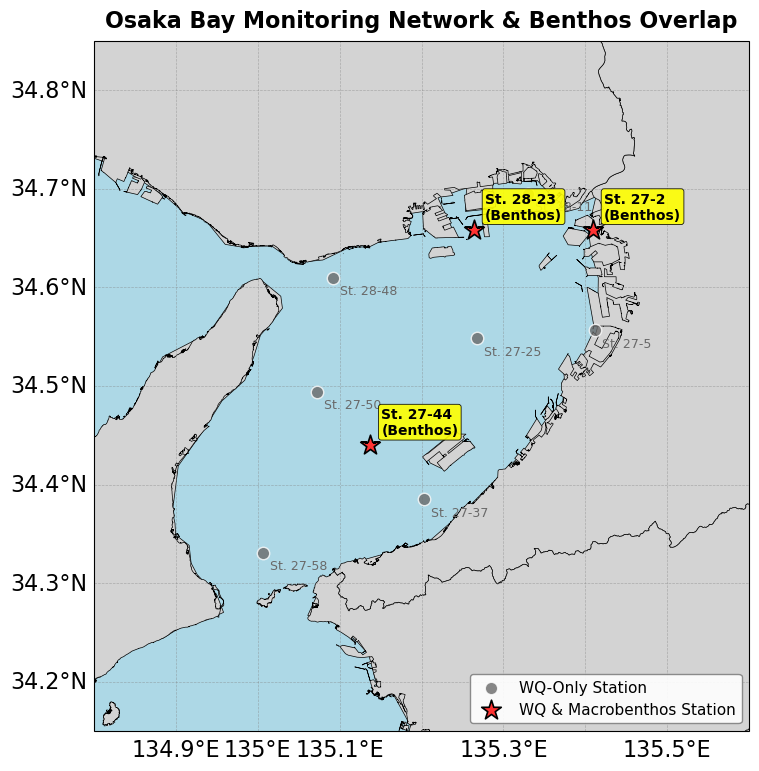

In [13]:
# Extract unique water quality stations in Osaka Bay
wq_osaka = merged_gdf[merged_gdf['division'] == 'Osaka Bay'][['prefectuei', 'renban', 'latitude', 'longitude']].drop_duplicates().dropna()
wq_osaka = wq_osaka.drop_duplicates(subset=['prefectuei', 'renban'])

# Get keys of active benthos stations
benthos_keys = set(zip(df_bio['ken'].astype(int), df_bio['ten'].astype(int)))

# Setup Cartopy map
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# Cartopy background elements
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# High-resolution land boundary
land_boundary_file = MappingConfig.get_boundary_file(MappingConfig.load_target_region())
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / land_boundary_file
if land_boundary_path.exists():
    sis_land_boundary = gpd.read_file(land_boundary_path)
    if sis_land_boundary.crs != "EPSG:4326":
        sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")
    sis_land_boundary.plot(
        ax=ax,
        facecolor=MappingConfig.COLOR_LAND,
        edgecolor=MappingConfig.COLOR_LAND_EDGE,
        linewidth=MappingConfig.LINEWIDTH_LAND,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_LAND
    )

# Gridlines configuration
gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, 
                  color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, 
                  linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
gl.top_labels = False
gl.right_labels = False

# Crop viewport to Osaka Bay
ax.set_extent([134.8, 135.6, 34.15, 34.85], crs=ccrs.PlateCarree())

# Plot WQ-only and WQ+Benthos stations
for _, row in wq_osaka.iterrows():
    k_val, t_val = int(row['prefectuei']), int(row['renban'])
    lat, lon = row['latitude'], row['longitude']
    
    if (k_val, t_val) in benthos_keys:
        # Benthos and WQ Station Overlap
        ax.scatter(lon, lat, color='#ff3333', s=220, marker='*', edgecolor='black', linewidth=1.2,
                   transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS,
                   label='WQ & Macrobenthos Station' if 'WQ & Macrobenthos Station' not in ax.get_legend_handles_labels()[1] else "")
        ax.annotate(f"St. {k_val}-{t_val}\n(Benthos)", xy=(lon, lat), xytext=(8, 8), textcoords='offset points',
                    fontsize=10, fontweight='bold', color='black',
                    bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.9, ec="black", lw=0.6),
                    zorder=10, transform=ccrs.PlateCarree())
    else:
        # Water Quality only
        ax.scatter(lon, lat, color='dimgray', s=80, marker='o', edgecolor='white', linewidth=1.0, alpha=0.8,
                   transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_PREDICTED,
                   label='WQ-Only Station' if 'WQ-Only Station' not in ax.get_legend_handles_labels()[1] else "")
        ax.annotate(f"St. {k_val}-{t_val}", xy=(lon, lat), xytext=(5, -12), textcoords='offset points',
                    fontsize=9, color='dimgray', zorder=8, transform=ccrs.PlateCarree())

ax.set_title("Osaka Bay Monitoring Network & Benthos Overlap", fontsize=16, pad=10, fontweight='bold')
ax.legend(loc='lower right', fontsize=11, framealpha=0.9, facecolor='white', edgecolor='gray')
plt.tight_layout()
plt.show()

## 2. Benthic Biodiversity Metrics
We calculate zero-catch preserved true Shannon Diversity and prepare a zero-adjusted Bray-Curtis dissimilarity matrix.

In [3]:
bio_melted = []
for i in range(1, 63):
    cols = ['sample_id', f'学名{i}', f'個体数{i}']
    if all(c in df_bio.columns for c in cols):
        sub = df_bio[cols].copy()
        sub.columns = ['sample_id', 'species', 'abundance']
        bio_melted.append(sub)

df_bio_long = pd.concat(bio_melted, ignore_index=True)
df_bio_long = df_bio_long.dropna(subset=['species'])
df_bio_long['species'] = df_bio_long['species'].astype(str).str.strip()
df_bio_long = df_bio_long[~df_bio_long['species'].isin(['nan', '', 'None'])]
df_bio_long['abundance'] = pd.to_numeric(df_bio_long['abundance'], errors='coerce').fillna(0)

# Pivot to wide format
df_pivot = df_bio_long.pivot_table(index='sample_id', columns='species', values='abundance', aggfunc='sum').fillna(0)
all_samples = df_bio['sample_id'].unique()
df_pivot = df_pivot.reindex(all_samples).fillna(0)

def calc_shannon(row):
    p = row[row > 0] / row.sum()
    if len(p) == 0:
        return 0.0
    return -np.sum(p * np.log(p))

df_bio['shannon_index'] = df_bio['sample_id'].map(lambda sid: calc_shannon(df_pivot.loc[sid]))
df_bio['total_abundance'] = df_bio['sample_id'].map(lambda sid: df_pivot.loc[sid].sum())
df_bio['richness'] = df_bio['sample_id'].map(lambda sid: (df_pivot.loc[sid] > 0).sum())

# NMDS Ordination with Zero-Adjusted Bray-Curtis
df_pivot_za = df_pivot.copy()
df_pivot_za['Dummy_Species_ZA'] = 1

bc_dist = squareform(pdist(df_pivot_za.values, metric='braycurtis'))
mds = MDS(n_components=2, metric=False, dissimilarity='precomputed', random_state=42)
nmds_coords = mds.fit_transform(bc_dist)

df_bio_unique = df_bio.drop_duplicates(subset=['sample_id']).set_index('sample_id')
df_bio_unique = df_bio_unique.loc[df_pivot_za.index] 
df_bio_unique['NMDS1'] = nmds_coords[:, 0]
df_bio_unique['NMDS2'] = nmds_coords[:, 1]
df_bio = df_bio_unique.reset_index()

print("Calculated biodiversity metrics and NMDS coordinates.")

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


Calculated biodiversity metrics and NMDS coordinates.


## 3. Spatial Interpolation (Ordinary Kriging with GEBCO)

In [4]:
gebco_file = next(ProjectPaths.BATHYMETRY_GEBCO_DIR.glob("*.nc"))
ds_gebco = xr.open_dataset(gebco_file)
ds_osaka = ds_gebco.sel(lon=slice(134.8, 135.6), lat=slice(34.15, 34.85))

# Downsample by factor of 3 to speed up Kriging (approx 1.5km resolution)
ds_osaka = ds_osaka.isel(lon=slice(None, None, 3), lat=slice(None, None, 3))

lon_g = ds_osaka.lon.values
lat_g = ds_osaka.lat.values
depth_g = -ds_osaka.elevation.values
grid_x, grid_y = np.meshgrid(lon_g, lat_g)

print(f"Downsampled grid shape: {grid_x.shape}")

# Land Masking
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_simplified.shp'
sis_water_boundary = gpd.read_file(water_boundary_path)
if sis_water_boundary.crs != 'EPSG:4326':
    sis_water_boundary = sis_water_boundary.to_crs('EPSG:4326')

prepared_poly = prep(sis_water_boundary.geometry.union_all())
grid_points = [Point(x, y) for x, y in zip(grid_x.flatten(), grid_y.flatten())]
water_mask_poly = np.array([prepared_poly.contains(pt) for pt in grid_points]).reshape(grid_x.shape)

valid_mask = water_mask_poly & (depth_g >= 5.0)

def do_kriging(year_data, lon_arr, lat_arr, mask):
    Z = np.full(mask.shape, np.nan)
    if len(year_data) < 3:
        return Z
    OK = OrdinaryKriging(
        year_data.geometry.x.values, 
        year_data.geometry.y.values, 
        year_data['do_'].values,
        variogram_model='spherical',
        nlags=6,
        enable_plotting=False
    )
    z, _ = OK.execute('grid', lon_arr, lat_arr)
    Z = np.where(mask, z, np.nan)
    return Z

available_years = sorted(summer_wq['surveyyear'].unique())
all_Z = {}

for y in available_years:
    df_y = summer_wq[summer_wq['surveyyear'] == y].dropna(subset=['do_'])
    stations_gpd = gpd.GeoDataFrame(df_y, geometry=gpd.points_from_xy(df_y.longitude, df_y.latitude), crs="EPSG:4326")
    all_Z[y] = do_kriging(stations_gpd, lon_g, lat_g, valid_mask)

print("Kriging completed for all available years.")

Downsampled grid shape: (56, 64)
Kriging completed for all available years.


## 4. Dynamic Hypoxia Exposure

In [5]:
valid_iy, valid_ix = np.where(valid_mask)
valid_coords = np.column_stack([grid_x[valid_iy, valid_ix], grid_y[valid_iy, valid_ix]])
water_tree = cKDTree(valid_coords)

bio_coords = np.column_stack([df_bio['lon_clean'], df_bio['lat_clean']])
_, bio_nearest_idx = water_tree.query(bio_coords)

df_bio['concurrent_do'] = np.nan
df_bio['exposure_3yr_freq'] = np.nan

for idx, row in df_bio.iterrows():
    iy = valid_iy[bio_nearest_idx[idx]]
    ix = valid_ix[bio_nearest_idx[idx]]
    Y = int(row['Year'])
    
    if Y in all_Z and not np.isnan(all_Z[Y][iy, ix]):
        df_bio.at[idx, 'concurrent_do'] = all_Z[Y][iy, ix]
    
    do_vals = [all_Z[y_lag][iy, ix] for y_lag in range(Y-3, Y+1) if y_lag in all_Z and not np.isnan(all_Z[y_lag][iy, ix])]
    if do_vals:
        df_bio.at[idx, 'exposure_3yr_freq'] = (sum(1 for v in do_vals if v <= 2.0) / len(do_vals)) * 100.0

def classify_exposure(freq):
    if pd.isna(freq):
        return 'Unknown'
    if freq == 0:
        return 'Normoxic (0%)'
    elif freq <= 50:
        return 'Moderate (1-50%)'
    else:
        return 'Severe (>50%)'

df_bio['Exposure_Group'] = df_bio['exposure_3yr_freq'].apply(classify_exposure)
print(df_bio['Exposure_Group'].value_counts())

Exposure_Group
Normoxic (0%)       486
Severe (>50%)       366
Moderate (1-50%)    223
Unknown               1
Name: count, dtype: int64


## 5. Statistical Analysis

In [6]:
groups = [
    df_bio[df_bio['Exposure_Group'] == 'Normoxic (0%)']['shannon_index'].dropna(),
    df_bio[df_bio['Exposure_Group'] == 'Moderate (1-50%)']['shannon_index'].dropna(),
    df_bio[df_bio['Exposure_Group'] == 'Severe (>50%)']['shannon_index'].dropna()
]

stat, p = kruskal(*groups)
print(f"Kruskal-Wallis H-test (Shannon across Exposure): p-value = {p:.4e}")

df_bio_valid = df_bio.dropna(subset=['concurrent_do'])
env_dist = squareform(pdist(df_bio_valid[['concurrent_do']].values, metric='euclidean'))

df_pivot_valid = df_pivot_za.loc[df_bio_valid['sample_id']]
bc_dist_valid = squareform(pdist(df_pivot_valid.values, metric='braycurtis'))

mask_tri = np.triu(np.ones(env_dist.shape, dtype=bool), k=1)
r, p_mantel = pearsonr(env_dist[mask_tri], bc_dist_valid[mask_tri])
print(f"Mantel Test (Pearson R between DO diff and Bray-Curtis dissim): r={r:.4f}, p={p_mantel:.4e}")

Kruskal-Wallis H-test (Shannon across Exposure): p-value = 2.4340e-20
Mantel Test (Pearson R between DO diff and Bray-Curtis dissim): r=0.1559, p=0.0000e+00


## 6. Visualizations

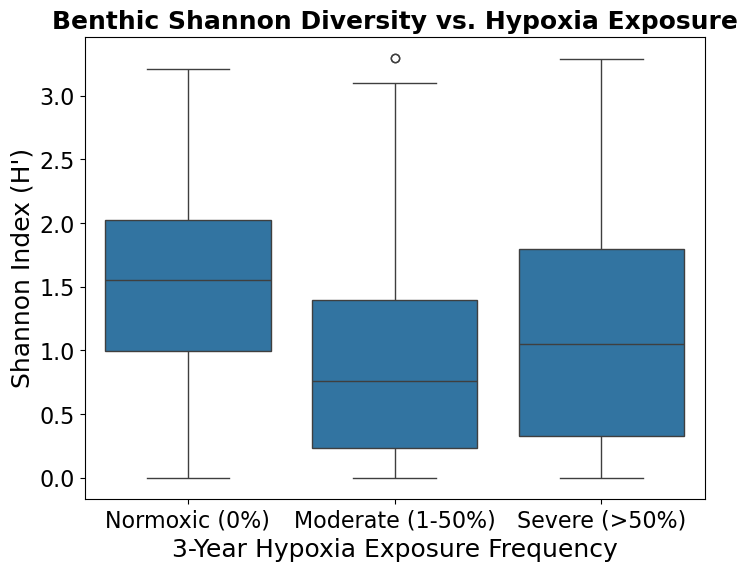

In [7]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Exposure_Group', y='shannon_index', data=df_bio, order=['Normoxic (0%)', 'Moderate (1-50%)', 'Severe (>50%)'])
plt.title('Benthic Shannon Diversity vs. Hypoxia Exposure', fontweight='bold')
plt.ylabel("Shannon Index (H')")
plt.xlabel("3-Year Hypoxia Exposure Frequency")
plt.show()

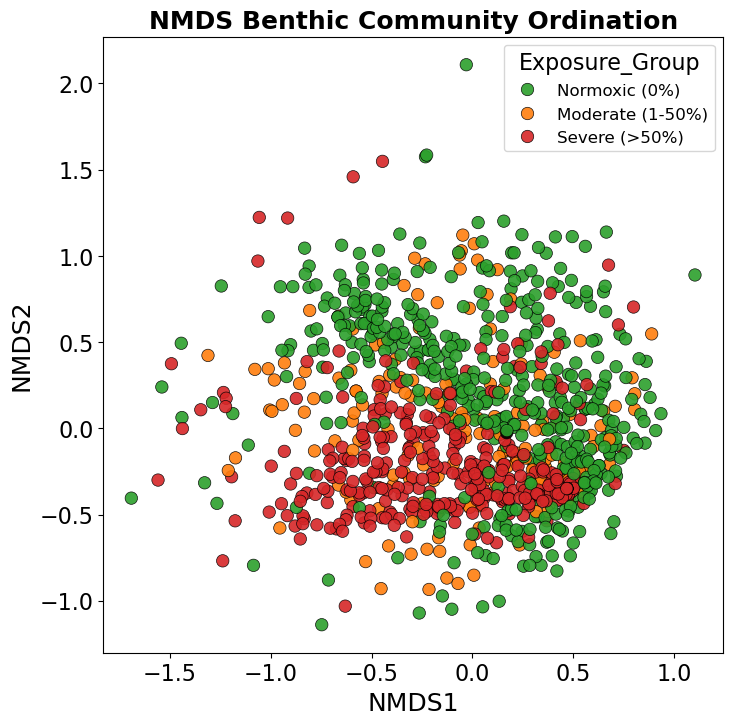

In [8]:
plt.figure(figsize=(8, 8))
sns.scatterplot(
    x='NMDS1', y='NMDS2', hue='Exposure_Group',
    hue_order=['Normoxic (0%)', 'Moderate (1-50%)', 'Severe (>50%)'],
    palette=['#2ca02c', '#ff7f0e', '#d62728'],
    s=80, data=df_bio, alpha=0.9, edgecolor='black', linewidth=0.5
)
plt.title('NMDS Benthic Community Ordination', fontweight='bold')
plt.show()

### Visualization 1: Map of Interpolated DO and Benthic Diversity
This map shows the interpolated bottom DO for the most recent year with available data, overlaid with the biological sampling stations colored by their Shannon Diversity index.

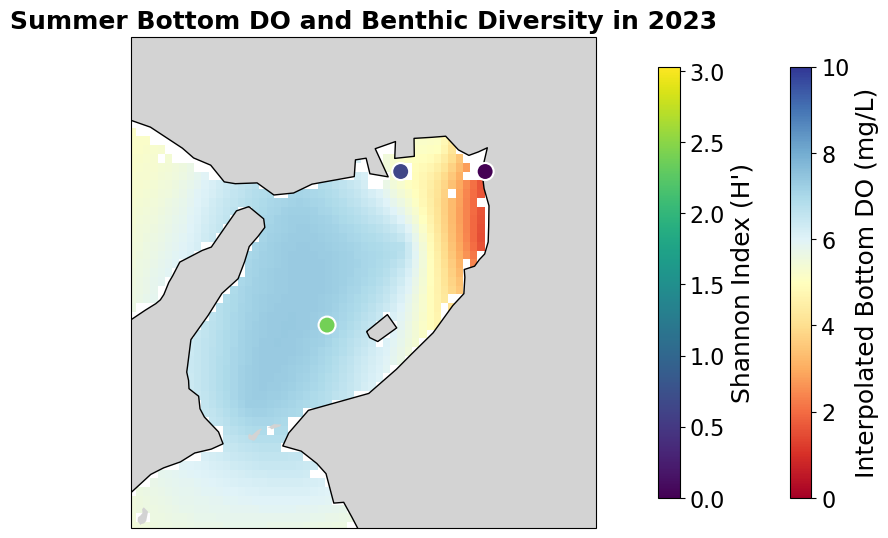

In [9]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

latest_year = max(all_Z.keys())
Z_latest = all_Z[latest_year]

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.Mercator())
ax.set_extent([134.8, 135.6, 34.15, 34.85], crs=ccrs.PlateCarree())

# Add land and coastline
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cfeature.COASTLINE, zorder=2)

# Plot interpolated DO
pm = ax.pcolormesh(grid_x, grid_y, Z_latest, transform=ccrs.PlateCarree(), cmap='RdYlBu', vmin=0, vmax=10, shading='auto', zorder=1)
cbar = plt.colorbar(pm, ax=ax, shrink=0.7)
cbar.set_label('Interpolated Bottom DO (mg/L)')

# Overlay summer stations from the latest year (filtering months 6-9)
df_bio_latest = df_bio[(df_bio['Year'] == latest_year) & (df_bio['date'].dt.month.isin([6, 7, 8, 9]))]
if not df_bio_latest.empty:
    sc = ax.scatter(df_bio_latest['lon_clean'], df_bio_latest['lat_clean'], c=df_bio_latest['shannon_index'], cmap='viridis', 
                    transform=ccrs.PlateCarree(), s=150, edgecolor='white', linewidth=1.5, zorder=5)
    cbar2 = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.1)
    cbar2.set_label("Shannon Index (H')")

plt.title(f'Summer Bottom DO and Benthic Diversity in {latest_year}', fontweight='bold')
plt.show()

### Visualization 2: Richness and Abundance across Exposure Groups
We compare species richness and total abundance across our dynamically calculated hypoxia exposure groups.

/tmp/ipykernel_5479/1264761675.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exposure_Group', y='richness', data=df_bio, order=['Normoxic (0%)', 'Moderate (1-50%)', 'Severe (>50%)'], ax=axes[0], palette=['#2ca02c', '#ff7f0e', '#d62728'])
/tmp/ipykernel_5479/1264761675.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exposure_Group', y='total_abundance', data=df_bio, order=['Normoxic (0%)', 'Moderate (1-50%)', 'Severe (>50%)'], ax=axes[1], palette=['#2ca02c', '#ff7f0e', '#d62728'])


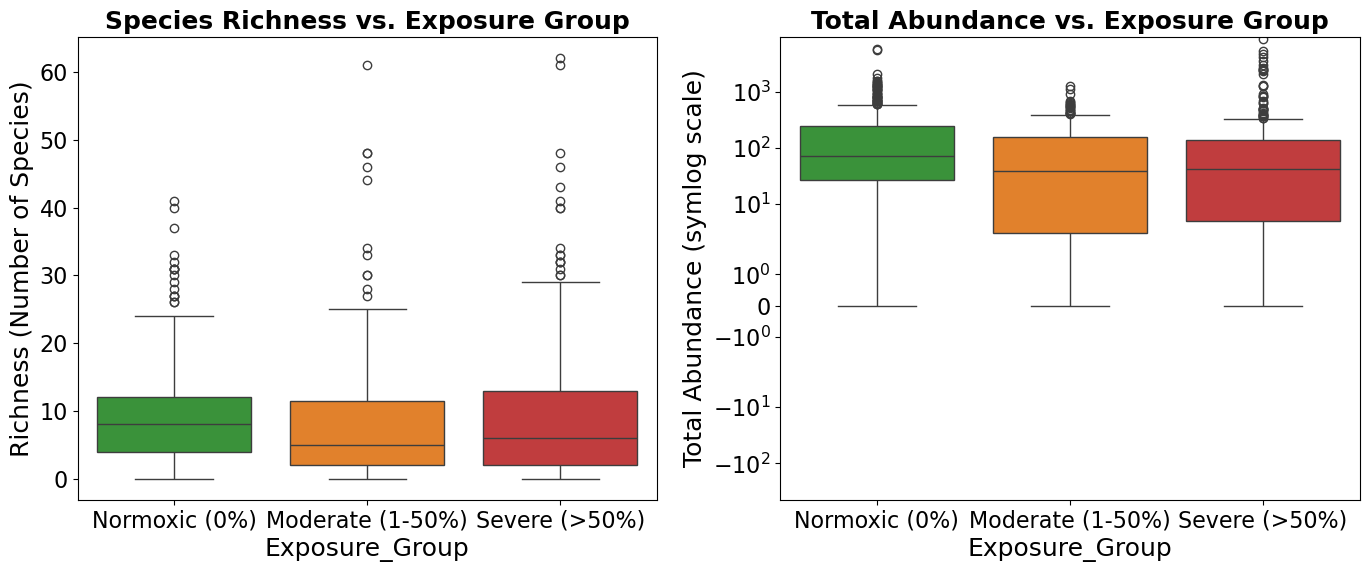

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(x='Exposure_Group', y='richness', data=df_bio, order=['Normoxic (0%)', 'Moderate (1-50%)', 'Severe (>50%)'], ax=axes[0], palette=['#2ca02c', '#ff7f0e', '#d62728'])
axes[0].set_title('Species Richness vs. Exposure Group', fontweight='bold')
axes[0].set_ylabel('Richness (Number of Species)')

sns.boxplot(x='Exposure_Group', y='total_abundance', data=df_bio, order=['Normoxic (0%)', 'Moderate (1-50%)', 'Severe (>50%)'], ax=axes[1], palette=['#2ca02c', '#ff7f0e', '#d62728'])
axes[1].set_yscale('symlog')
axes[1].set_title('Total Abundance vs. Exposure Group', fontweight='bold')
axes[1].set_ylabel('Total Abundance (symlog scale)')

plt.tight_layout()
plt.show()

### Visualization 3: Top Dominant Species per Exposure Group
This plot reveals how the community composition shifts by highlighting the most abundant species within each exposure group.

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


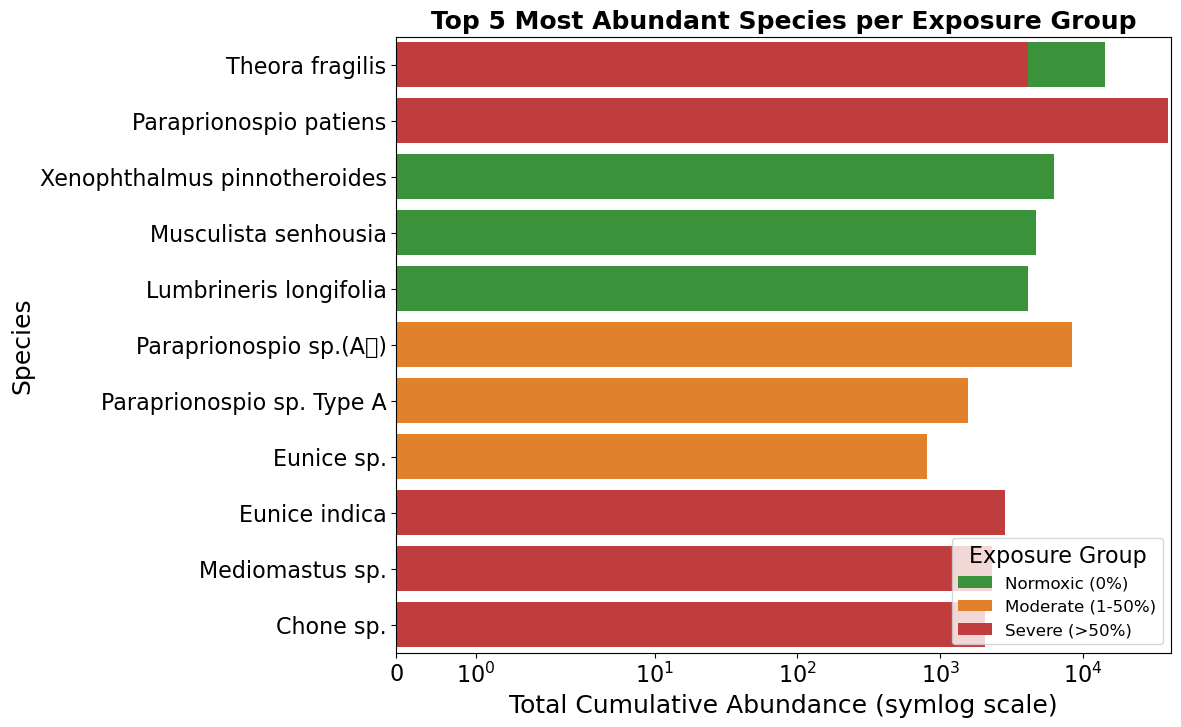

In [11]:
# Merge df_bio_long with Exposure_Group
df_bio_long_exp = df_bio_long.merge(df_bio[['sample_id', 'Exposure_Group']], on='sample_id', how='left')
df_bio_long_exp = df_bio_long_exp.dropna(subset=['Exposure_Group'])

# Group by Exposure Group and Species
species_by_group = df_bio_long_exp.groupby(['Exposure_Group', 'species'])['abundance'].sum().reset_index()

# For each group, get top 5 species
top_species_list = []
for group in ['Normoxic (0%)', 'Moderate (1-50%)', 'Severe (>50%)']:
    group_data = species_by_group[species_by_group['Exposure_Group'] == group]
    top_species = group_data.nlargest(5, 'abundance')
    top_species_list.append(top_species)

top_species_df = pd.concat(top_species_list)

plt.figure(figsize=(10, 8))
sns.barplot(x='abundance', y='species', hue='Exposure_Group', data=top_species_df, dodge=False, palette=['#2ca02c', '#ff7f0e', '#d62728'])
plt.title('Top 5 Most Abundant Species per Exposure Group', fontweight='bold')
plt.xscale('symlog')
plt.xlabel('Total Cumulative Abundance (symlog scale)')
plt.ylabel('Species')
plt.legend(title='Exposure Group', loc='lower right')
plt.show()

### Visualization 4: Continuous Relationship between Exposure Frequency and Diversity
A non-parametric LOWESS curve to visualize the continuous decline in biodiversity with increasing historical exposure.

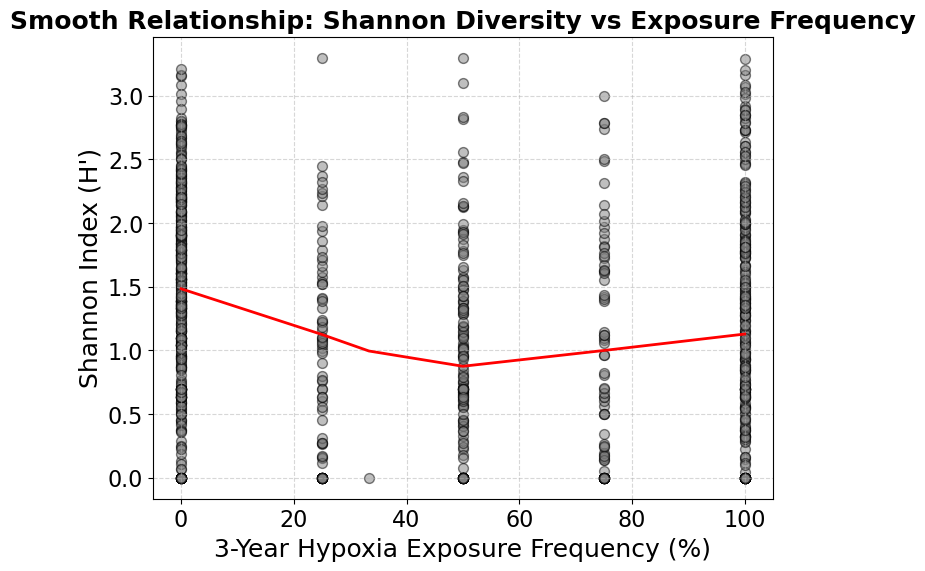

In [12]:
plt.figure(figsize=(8, 6))
sns.regplot(x='exposure_3yr_freq', y='shannon_index', data=df_bio, lowess=True, 
            scatter_kws={'alpha':0.5, 'color':'gray', 's': 50, 'edgecolor': 'black'}, 
            line_kws={'color':'red', 'linewidth': 2})
plt.title('Smooth Relationship: Shannon Diversity vs Exposure Frequency', fontweight='bold')
plt.xlabel('3-Year Hypoxia Exposure Frequency (%)')
plt.ylabel("Shannon Index (H')")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()